<a href="https://colab.research.google.com/github/neskverna/cpp-practice-2026/blob/main/HW5/airapetyan_v_g.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Распознавание лиц и глаз каскадами Хаара (C++ и OpenCV)

**Задание**
1. На основе ноутбука сделать загрузку фотографий людей для распознавания лиц и глаз.
2. Провести эксперимент несколько раз с разными фотографиями (в разных ячейках).
3. Сравнить количество лиц и глаз на фото и количество, распознанное каскадами. Объяснить, почему так получается.

**Как запустить:** «Среда выполнения» → «Выполнить все». Разделы 1–4 выполняются сами.
В разделе 6 можно загрузить свою фотографию с компьютера.

## 1. Установка

In [1]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [2]:
# В Colab сейчас стоит OpenCV 5.x, а в нём каскады Хаара убраны из Python-пакета (нет cv2.CascadeClassifier).
# Ставим OpenCV 4 — ту же версию, что и C++-библиотека выше. Эту ячейку нужно запускать до первого import cv2.
!pip uninstall -y -q opencv-python opencv-contrib-python opencv-python-headless
!pip install -q opencv-python-headless==4.14.0.94

## 2. Загрузка изображения по URL и обработка на C++

In [3]:
%%writefile main.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

int main() {
    const char* image_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    CURL* curl_handle;
    CURLcode res;
    std::vector<uchar> image_data;

    curl_global_init(CURL_GLOBAL_DEFAULT);
    curl_handle = curl_easy_init();

    if(curl_handle) {
        curl_easy_setopt(curl_handle, CURLOPT_URL, image_url);
        curl_easy_setopt(curl_handle, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl_handle, CURLOPT_WRITEDATA, &image_data);
        curl_easy_setopt(curl_handle, CURLOPT_USERAGENT, "libcurl-agent/1.0");

        res = curl_easy_perform(curl_handle);

        if(res != CURLE_OK) {
            std::cerr << "curl_easy_perform() failed: " << curl_easy_strerror(res) << std::endl;
            curl_easy_cleanup(curl_handle);
            curl_global_cleanup();
            return 1;
        }
        curl_easy_cleanup(curl_handle);
    }
    curl_global_cleanup();

    std::cout << "Downloaded " << image_data.size() << " bytes." << std::endl;

    cv::Mat image = cv::imdecode(image_data, cv::IMREAD_COLOR);

    if (image.empty()) {
        std::cerr << "Could not decode image!" << std::endl;
        return 1;
    }

    std::cout << "Image decoded successfully: " << image.cols << "x" << image.rows << std::endl;

    // Сохраняем оригинал, чтобы потом показать его в Python
    cv::imwrite("original_output.jpg", image);

    // Обработка: перевод в оттенки серого
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);

    cv::imwrite("gray_output.jpg", gray);
    std::cout << "Images saved as original_output.jpg and gray_output.jpg" << std::endl;

    return 0;
}

Writing main.cpp


In [4]:
!g++ main.cpp -o main $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17
!./main

Downloaded 91814 bytes.
Image decoded successfully: 512x512
Images saved as original_output.jpg and gray_output.jpg


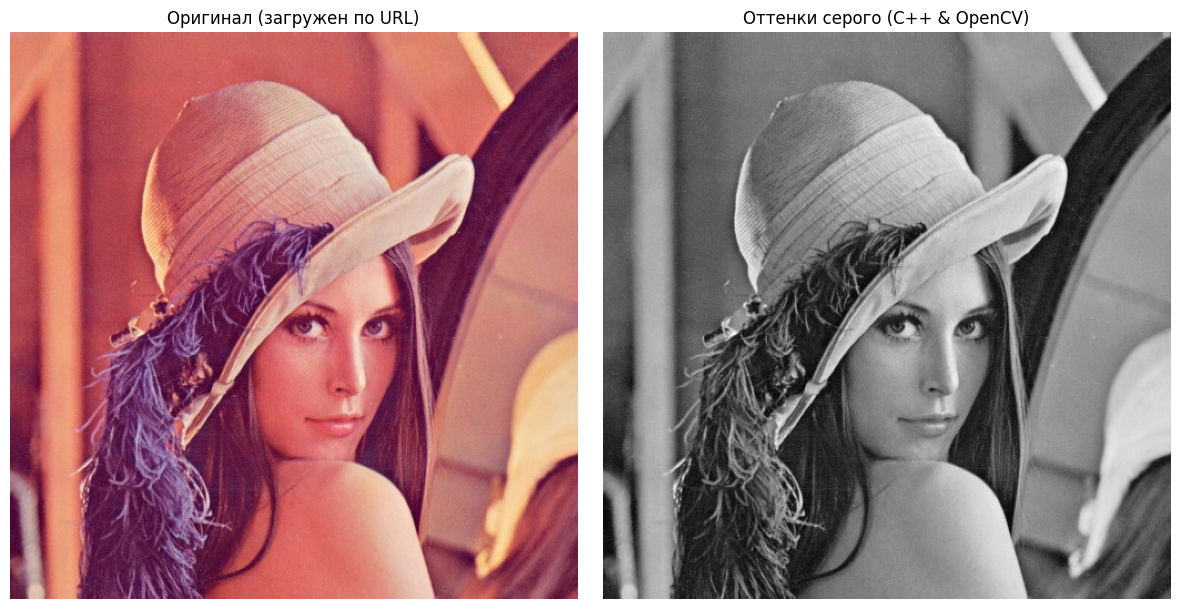

In [5]:
import matplotlib.pyplot as plt
import cv2

# Загружаем оба сохранённых изображения
img_original = cv2.imread('original_output.jpg')
img_gray = cv2.imread('gray_output.jpg', cv2.IMREAD_GRAYSCALE)

if img_original is not None and img_gray is not None:
    # Конвертируем оригинал из BGR (OpenCV) в RGB (Matplotlib)
    img_original_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(img_original_rgb)
    axes[0].set_title('Оригинал (загружен по URL)')
    axes[0].axis('off')

    axes[1].imshow(img_gray, cmap='gray')
    axes[1].set_title('Оттенки серого (C++ & OpenCV)')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Не удалось загрузить одно из изображений.")

### Поиск лиц и глаз программой на C++ (`detect_faces.cpp`)

In [6]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Универсальная загрузка: URL или локальный файл
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    // Источник: аргумент командной строки, иначе — URL по умолчанию
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    // Каскады
    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    // Подготовка
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    // Детекция лиц — вернёт ВСЕ найденные лица
    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
        /*scaleFactor*/  1.05,   // чуть меньше, чем 1.1 — ищем тщательнее (для групповых фото)
        /*minNeighbors*/ 5,
        /*flags*/        0,
        /*minSize*/      cv::Size(20, 20)   // маленькие лица тоже ловим
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;

    // Рисуем рамку + номер для каждого лица
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        // Подпись "Face N" над рамкой
        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        // Глаза ищем только в верхних 60% лица (там они и находятся)
        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 2;
    }
    return 0;
}

Writing detect_faces.cpp


In [7]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17
!./detect_faces

Loading: https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg
Image: 512x512
Detected faces: 1
Result saved: faces_detected.jpg


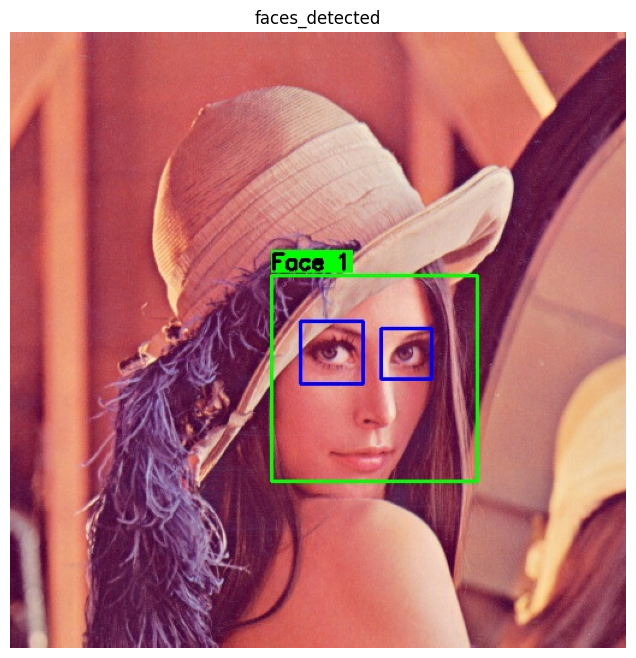

In [8]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

Так выглядит файл обученного каскада лиц (XML с признаками Хаара):

In [ ]:
!cat "/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml"

## 3. Эксперименты: распознавание лиц и глаз на разных фотографиях

Программа `detect_faces.cpp` печатает только количество лиц, а глаза лишь рисует.
Чтобы посчитать и лица, и глаза, ниже тот же алгоритм на Python с **теми же параметрами**, что в `detect_faces.cpp`:

* лица: `equalizeHist`, `scaleFactor = 1.05`, `minNeighbors = 5`, `minSize = 20×20`;
* глаза: только в верхних 60% лица, `scaleFactor = 1.1`, `minNeighbors = 10`.

Фотографии загружаются по ссылкам (общедоступные снимки с Wikimedia Commons и пример `messi5.jpg` из OpenCV),
поэтому ноутбук работает целиком через «Выполнить все». Свою фотографию с компьютера можно загрузить в разделе 6.

Зелёные рамки — найденные лица, синие — найденные глаза.

In [9]:
import cv2
import requests
import pandas as pd
import matplotlib.pyplot as plt

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
eye_cascade  = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
assert not face_cascade.empty() and not eye_cascade.empty(), 'Каскады не загрузились'

results = {}   # результаты всех экспериментов для итоговой таблицы


def download(url, filename):
    """Скачивает фотографию по ссылке и сохраняет в файл."""
    r = requests.get(url, headers={'User-Agent': 'cpp-cv-lab/1.0 (educational notebook)'}, timeout=60)
    r.raise_for_status()
    with open(filename, 'wb') as f:
        f.write(r.content)
    return filename


def detect_and_show(filename, title, true_faces, true_eyes):
    image = cv2.imread(filename)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.equalizeHist(gray)

    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=5,
                                          flags=0, minSize=(20, 20))
    eyes_found = 0
    for i, (x, y, w, h) in enumerate(faces, 1):
        cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(image, f'Face {i}', (x, max(y - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        top = gray[y:y + h * 6 // 10, x:x + w]                 # верхние 60% лица
        eyes = eye_cascade.detectMultiScale(top, scaleFactor=1.1, minNeighbors=10)
        eyes_found += len(eyes)
        for (ex, ey, ew, eh) in eyes:
            cv2.rectangle(image, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 0, 0), 2)

    plt.figure(figsize=(12, 9))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f'{title}: лиц найдено {len(faces)}, глаз найдено {eyes_found}')
    plt.axis('off')
    plt.show()

    print(f'Лиц на фото:  {true_faces:3d}   найдено каскадом: {len(faces):3d}')
    print(f'Глаз на фото: {true_eyes:3d}   найдено каскадом: {eyes_found:3d}')
    results[title] = {'Лиц на фото': true_faces, 'Лиц найдено': len(faces),
                      'Глаз на фото': true_eyes, 'Глаз найдено': eyes_found}

### Эксперимент 1. Портрет анфас
Один человек, лицо прямо, хорошее освещение (Альберт Эйнштейн, 1947).

На фото **лиц: 1, глаз: 2** (посчитано вручную).

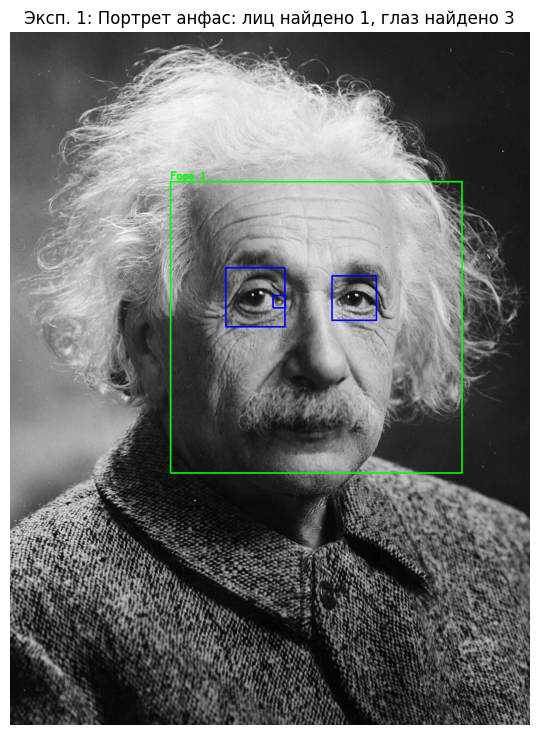

Лиц на фото:    1   найдено каскадом:   1
Глаз на фото:   2   найдено каскадом:   3


In [10]:
photo1 = download('https://commons.wikimedia.org/wiki/Special:FilePath/Albert_Einstein_Head.jpg?width=800', 'einstein.jpg')
detect_and_show(photo1, 'Эксп. 1: Портрет анфас', true_faces=1, true_eyes=2)

### Эксперимент 2. Портрет в очках
Один человек в очках, светлая одежда со складками (Махатма Ганди, 1931).

На фото **лиц: 1, глаз: 2** (посчитано вручную).

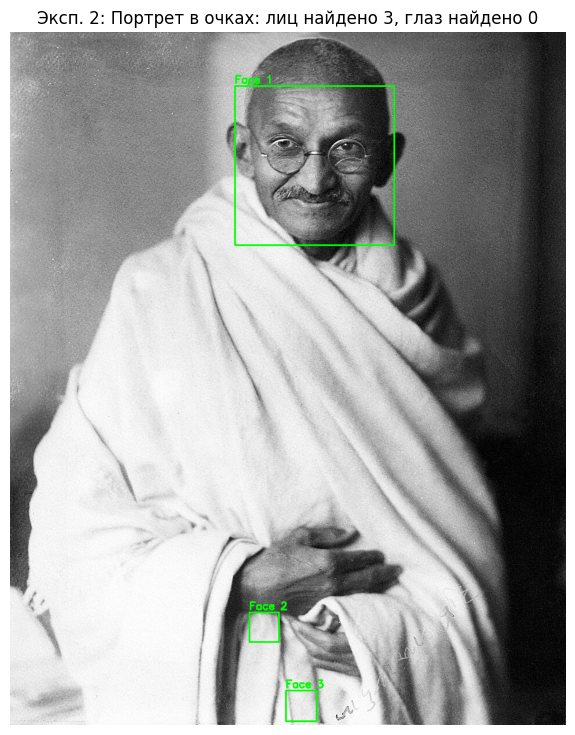

Лиц на фото:    1   найдено каскадом:   3
Глаз на фото:   2   найдено каскадом:   0


In [11]:
photo2 = download('https://commons.wikimedia.org/wiki/Special:FilePath/Mahatma-Gandhi,_studio,_1931.jpg?width=800', 'gandhi.jpg')
detect_and_show(photo2, 'Эксп. 2: Портрет в очках', true_faces=1, true_eyes=2)

### Эксперимент 3. Человек в движении
Футболист в прыжке: маленькое лицо, голова наклонена, пёстрый фон с трибунами.

На фото **лиц: 1, глаз: 2** (посчитано вручную).

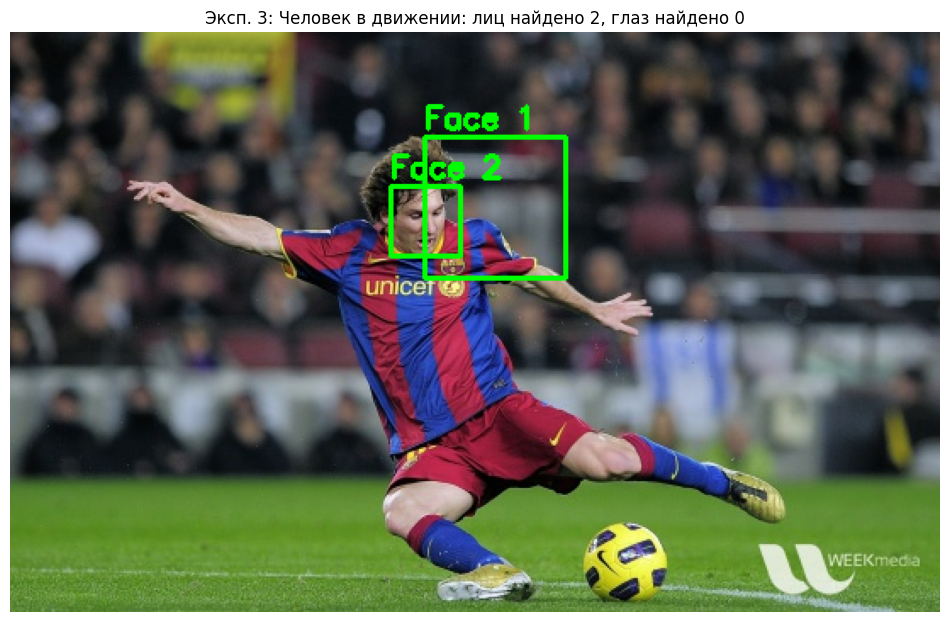

Лиц на фото:    1   найдено каскадом:   2
Глаз на фото:   2   найдено каскадом:   0


In [12]:
photo3 = download('https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/messi5.jpg', 'messi.jpg')
detect_and_show(photo3, 'Эксп. 3: Человек в движении', true_faces=1, true_eyes=2)

### Эксперимент 4. Четыре лица
Коллаж из четырёх крупных лиц (The Beatles, 1964): одно лицо повёрнуто вбок.

На фото **лиц: 4, глаз: 8** (посчитано вручную).

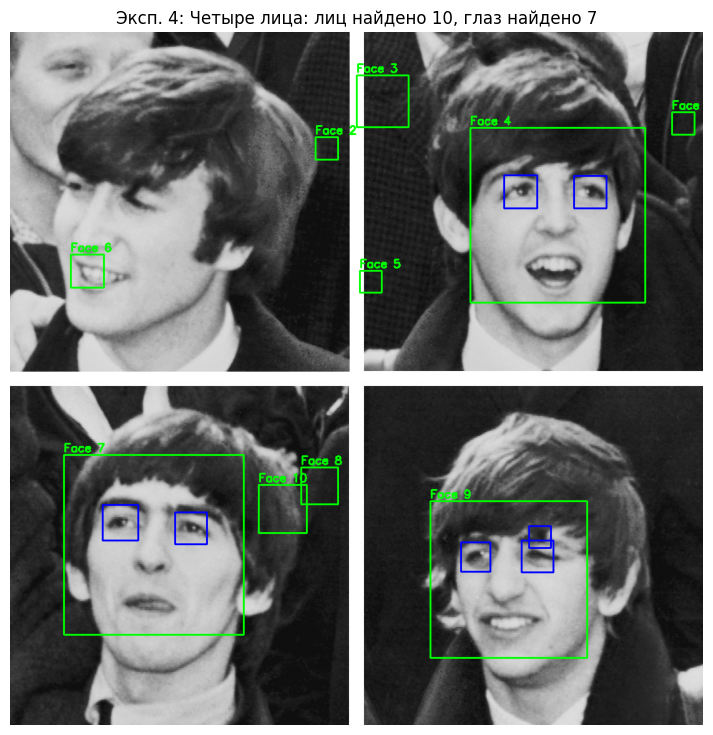

Лиц на фото:    4   найдено каскадом:  10
Глаз на фото:   8   найдено каскадом:   7


In [13]:
photo4 = download('https://commons.wikimedia.org/wiki/Special:FilePath/The_Beatles_members_at_New_York_City_in_1964.jpg?width=1200', 'beatles.jpg')
detect_and_show(photo4, 'Эксп. 4: Четыре лица', true_faces=4, true_eyes=8)

### Эксперимент 5. Групповое фото
Сольвеевский конгресс 1927 года: 29 человек, мелкие лица, у многих очки, на фоне здание.

На фото **лиц: 29, глаз: 58** (посчитано вручную).

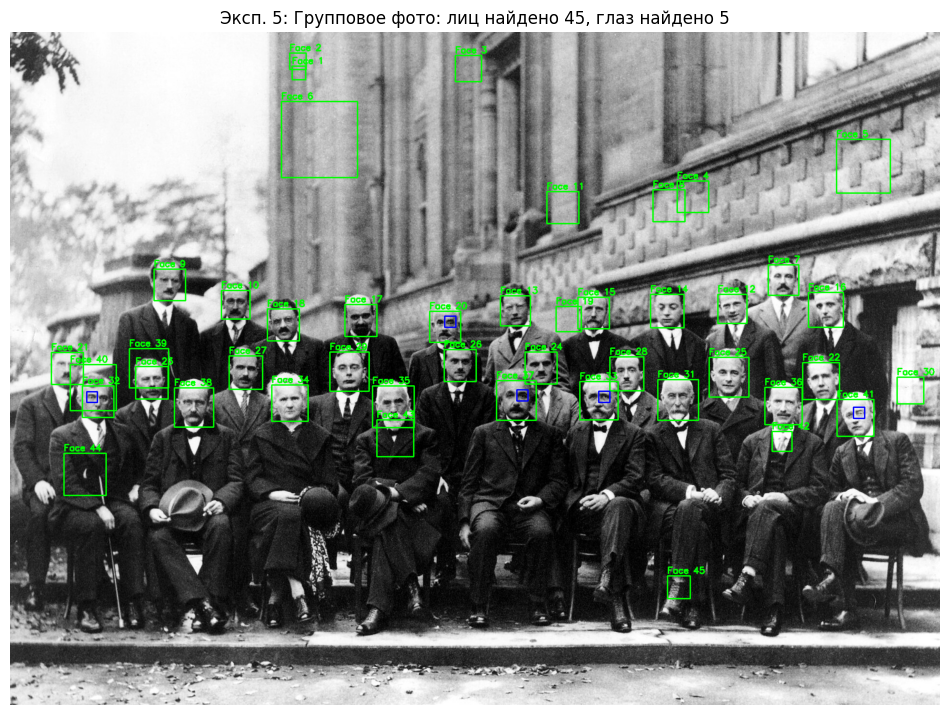

Лиц на фото:   29   найдено каскадом:  45
Глаз на фото:  58   найдено каскадом:   5


In [14]:
photo5 = download('https://commons.wikimedia.org/wiki/Special:FilePath/Solvay_conference_1927.jpg?width=1600', 'solvay.jpg')
detect_and_show(photo5, 'Эксп. 5: Групповое фото', true_faces=29, true_eyes=58)

## 4. Итоговая таблица

In [15]:
df = pd.DataFrame.from_dict(results, orient='index')
df['Ошибка по лицам'] = df['Лиц найдено'] - df['Лиц на фото']
df['Ошибка по глазам'] = df['Глаз найдено'] - df['Глаз на фото']
df

,Лиц на фото,Лиц найдено,Глаз на фото,Глаз найдено,Ошибка по лицам,Ошибка по глазам
Эксп. 1: Портрет анфас,1,1,2,3,0,1
Эксп. 2: Портрет в очках,1,3,2,0,2,-2
Эксп. 3: Человек в движении,1,2,2,0,1,-2
Эксп. 4: Четыре лица,4,10,8,7,6,-1
Эксп. 5: Групповое фото,29,45,58,5,16,-53


## 5. Вывод

| Эксперимент | Лиц на фото | Лиц найдено | Глаз на фото | Глаз найдено | Что видно на картинке |
|---|---|---|---|---|---|
| 1. Портрет анфас | 1 | 1 | 2 | 3 | лицо найдено верно; один глаз отмечен дважды |
| 2. Портрет в очках | 1 | 3 | 2 | 0 | лицо найдено, плюс 2 ложных «лица» в складках одежды; глаза за очками не найдены |
| 3. Человек в движении | 1 | 2 | 2 | 0 | лицо найдено, плюс 1 ложная рамка на голове и фоне; глаза не найдены |
| 4. Четыре лица | 4 | 10 | 8 | 7 | 3 лица верно, повёрнутое вбок лицо пропущено, 7 ложных рамок на волосах и одежде; 6 глаз верно, 1 ложный (бровь) |
| 5. Групповое фото | 29 | 45 | 58 | 5 | все 29 лиц найдены, но ещё 16 ложных (стена здания, шляпа, ботинки, бороды, двойные рамки); глаза почти не найдены |

Количество лиц и глаз, найденных каскадами, совпало с реальным только для лица на простом портрете анфас.
Почти везде есть два вида ошибок: **пропуски** (объект есть, но не найден) и **ложные срабатывания**
(найдено то, чего нет). Иногда они компенсируют друг друга: в эксперименте 4 найдено 7 глаз из 8,
но один из них — бровь, а не глаз. Поэтому сравнивать нужно не только числа, но и сами рамки.

**Почему так получается:**

1. **Каскад обучен на фронтальных лицах.** `haarcascade_frontalface_default` ищет лицо анфас,
   поэтому повёрнутое вбок лицо (эксперимент 4) пропускается.
2. **Признаки Хаара — это перепады яркости** (глаза темнее щёк, переносица светлее).
   Такой же узор случайно есть в складках одежды, волосах, окнах и кладке здания,
   поэтому появляются ложные «лица» (эксперименты 2, 4, 5).
3. **Мягкие параметры.** `scaleFactor = 1.05`, `minNeighbors = 5` и `minSize = 20×20` в программе подобраны так,
   чтобы найти даже мелкие лица на групповом фото. Поэтому все 29 человек найдены, но вместе с ними растёт
   и число ложных срабатываний. Строже параметры — меньше ложных, но больше пропусков.
4. **Глаза находятся хуже, чем лица.** Глаз — маленький объект, а каскад глаз обучен на окне 20×20 пикселей.
   На групповом фото лица всего 50–90 пикселей, глаза на них 10–15 пикселей, поэтому найдено 5 глаз из 58.
   Кроме того, `minNeighbors = 10` для глаз — строгий порог.
5. **Очки, наклон, движение.** Стёкла и оправа скрывают контраст глаза (эксперимент 2),
   у футболиста лицо маленькое и наклонено (эксперимент 3) — глаза не найдены.
6. **Глаза ищутся только внутри найденных лиц.** Если лицо пропущено, его глаза тоже пропадают;
   если «лицо» ложное, в нём могут найтись ложные «глаза». Иногда один и тот же глаз отмечается
   двумя рамками (эксперимент 1).

**Итог:** каскады Хаара работают быстро и хорошо находят крупные лица анфас при хорошем свете,
но ошибаются на повёрнутых и мелких лицах, на очках и на сложном фоне. Поэтому количество найденных
лиц и глаз почти всегда отличается от реального, а результат сильно зависит от параметров `detectMultiScale`.
Современные нейросетевые детекторы (например, DNN-модуль OpenCV) справляются с такими фото значительно лучше.

## 6. Загрузка своей фотографии с компьютера

Запустите ячейку ниже, нажмите **«Выбрать файлы»** и выберите фото (JPG или PNG).
Имя загруженного файла подставляется в программу `detect_faces` автоматически,
ничего менять в коде не нужно.

In [16]:
from google.colab import files

uploaded = files.upload()
my_photo = next(iter(uploaded)) if uploaded else None
print('Загружен файл:', my_photo)

Saving Макет 10x15.jpg to Макет 10x15.jpg
Загружен файл: Макет 10x15.jpg


Loading: Макет 10x15.jpg
Image: 2410x3592
Detected faces: 11
Result saved: faces_detected.jpg


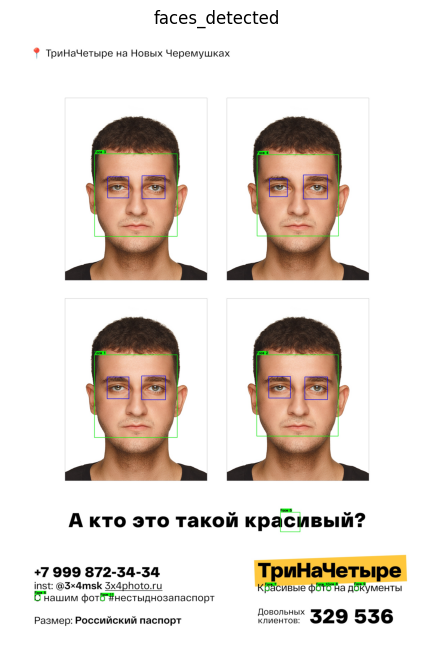

In [17]:
# Запускаем программу на C++ на загруженном фото (имя файла подставляется из переменной my_photo)
if my_photo:
    !./detect_faces "{my_photo}"

    img = cv2.imread('faces_detected.jpg')
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print('Фото не загружено')